In [1]:
from pathlib import Path

import pandas as pd

data_dir = Path("CMAPSSData")
columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]

datasets = {}

for subset in ("train", "test"):
    for fd in range(1, 5):
        name = f"{subset}_FD{fd:03d}"
        path = data_dir / f"{name}.txt"
        datasets[name] = pd.read_csv(
            path,
            sep=r"\s+",
            header=None,
            names=columns,
        )

# RUL files contain one target value per corresponding test engine.
rul_targets = {
    f"RUL_FD{fd:03d}": pd.read_csv(
        data_dir / f"RUL_FD{fd:03d}.txt",
        sep=r"\s+",
        header=None,
        names=["RUL"],
    )
    for fd in range(1, 5)
}

for name, df in datasets.items():
    print(f"\n{'=' * 80}\n{name}: {df.shape[0]} rows × {df.shape[1]} columns")

    print("\nVariable types:")
    print(df.dtypes.to_string())

    missing = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
    })
    print("\nMissingness:")
    print(missing.to_string())

    print("\nDescriptive statistics:")
    print(df.describe().T.to_string())

    print("\nUnique-value counts:")
    print(df.nunique().to_string())

    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()
    print("\nCategorical columns and values:")
    if categorical_columns:
        for column in categorical_columns:
            print(f"{column}: {df[column].dropna().unique().tolist()}")
    else:
        print("None detected; the loaded variables are numeric.")

    print(
        "\nEngine IDs (identifiers, not categorical features):",
        sorted(df["engine_id"].unique().tolist()),
    )

for name, df in rul_targets.items():
    print(f"\n{name}: {len(df)} RUL values")
    print(df.describe().to_string())
    print("Missing values:", int(df["RUL"].isna().sum()))


train_FD001: 20631 rows × 26 columns

Variable types:
engine_id      int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64

Missingness:
           missing_count  missing_percent
engine_id              0              0.0
cycle                  0              0.0
setting_1              0              0.0
setting_2              0              0.0
setting_3              0              0.0
sensor_1               0              0.0
sensor_2               0              0.0
sensor_3               0              0.0
sensor_

Engine-level sample size: 100
Model summary, coefficients, confidence intervals, and Wald tests:
                      coef   exp(coef)  se(coef)  coef lower 95%  coef upper 95%           z              p
param  covariate                                                                                           
alpha_ sensor_11  0.002194    1.002197  0.038814       -0.073880        0.078269    0.056532   9.549176e-01
       sensor_12  0.036828    1.037514  0.035059       -0.031886        0.105541    1.050457   2.935080e-01
       sensor_13  0.021898    1.022139  0.040122       -0.056740        0.100536    0.545784   5.852142e-01
       sensor_14 -0.058192    0.943469  0.040801       -0.138160        0.021777   -1.426237   1.537998e-01
       sensor_15  0.006083    1.006102  0.031045       -0.054763        0.066929    0.195952   8.446478e-01
       sensor_17  0.001405    1.001406  0.024366       -0.046351        0.049161    0.057673   9.540089e-01
       sensor_2  -0.040514    0.960295 

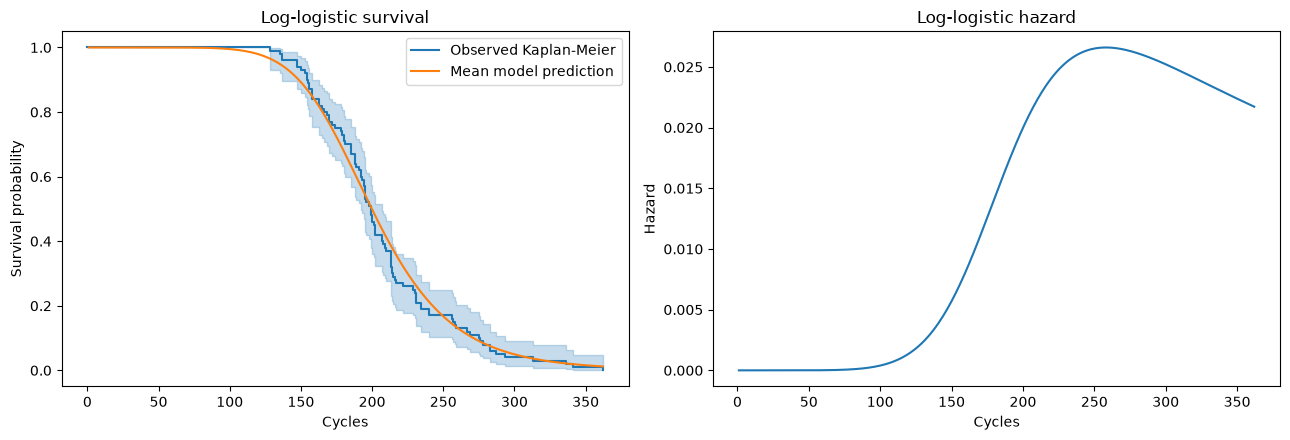

In [2]:
# Fit a log-logistic proportional-odds model using one baseline record per FD001 engine.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter, LogLogisticAFTFitter
from lifelines.utils import concordance_index

columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
fd001_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)

baseline = (
    fd001_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False)
    .first()
)
failure_times = (
    fd001_raw.groupby("engine_id", as_index=False)["cycle"]
    .max()
    .rename(columns={"cycle": "T"})
)
fd001_life = baseline[["engine_id", *columns[5:]]].merge(
    failure_times, on="engine_id", validate="one_to_one"
)
fd001_life["event"] = 1

sensor_cols = [
    col for col in columns[5:]
    if fd001_life[col].nunique() > 1
]
fd001_X = fd001_life[sensor_cols].copy()
fd001_X = (fd001_X - fd001_X.mean()) / fd001_X.std(ddof=0)
fd001_model_data = pd.concat(
    [fd001_life[["T", "event"]], fd001_X], axis=1
)

assert len(fd001_raw) == 20631
assert fd001_life["engine_id"].nunique() == 100
assert fd001_life["event"].eq(1).all()

aft_model = LogLogisticAFTFitter(penalizer=0.1)
aft_model.fit(fd001_model_data, duration_col="T", event_col="event")

print("Engine-level sample size:", len(fd001_life))
print("Model summary, coefficients, confidence intervals, and Wald tests:")
print(
    aft_model.summary[
        ["coef", "exp(coef)", "se(coef)", "coef lower 95%",
         "coef upper 95%", "z", "p"]
    ].to_string()
)
print("AIC:", round(aft_model.AIC_, 2))
print(
    "Concordance index:",
    concordance_index(
        fd001_life["T"],
        aft_model.predict_median(fd001_X),
        event_observed=fd001_life["event"],
    ),
)
print("Likelihood-ratio test against the intercept-only model:")
print(aft_model.log_likelihood_ratio_test())
print(
    "Interpretation: this log-logistic AFT parameterization is a "
    "proportional-odds model. Positive alpha_ coefficients indicate "
    "longer survival; exp(coef) is the corresponding time ratio. "
    "The 0.1 ridge penalty stabilizes the sensor model."
)

timeline = np.arange(1, int(fd001_life["T"].max()) + 1)
aft_survival = aft_model.predict_survival_function(
    fd001_X, times=timeline
).mean(axis=1)
aft_hazard = aft_model.predict_hazard(
    fd001_X, times=timeline
).mean(axis=1)
fd001_km = KaplanMeierFitter().fit(
    fd001_life["T"],
    event_observed=fd001_life["event"],
    label="Observed Kaplan-Meier",
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fd001_km.plot_survival_function(ax=axes[0], ci_show=True)
axes[0].plot(timeline, aft_survival, label="Mean model prediction")
axes[0].set(
    title="Log-logistic survival",
    xlabel="Cycles",
    ylabel="Survival probability",
)
axes[0].legend()

axes[1].plot(timeline, aft_hazard)
axes[1].set(title="Log-logistic hazard", xlabel="Cycles", ylabel="Hazard")
fig.tight_layout()
plt.show()

Model summary, coefficients, confidence intervals, and Wald tests:
               coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%         z         p
covariate                                                                                   
sensor_2   0.213245   1.237688  0.122440       -0.026733        0.453223  1.741632  0.081573
sensor_3   0.095499   1.100208  0.107371       -0.114945        0.305943  0.889426  0.373774
sensor_4   0.091337   1.095638  0.145131       -0.193115        0.375788  0.629338  0.529128
sensor_6   0.113884   1.120623  0.099351       -0.080840        0.308609  1.146284  0.251678
sensor_7  -0.035151   0.965460  0.144506       -0.318377        0.248076 -0.243246  0.807815
sensor_8  -0.117316   0.889304  0.158808       -0.428573        0.193942 -0.738727  0.460073
sensor_9  -0.195848   0.822138  0.167392       -0.523930        0.132235 -1.169994  0.242003
sensor_11 -0.060333   0.941451  0.174232       -0.401821        0.281156 -0.346279  0.729133
sen

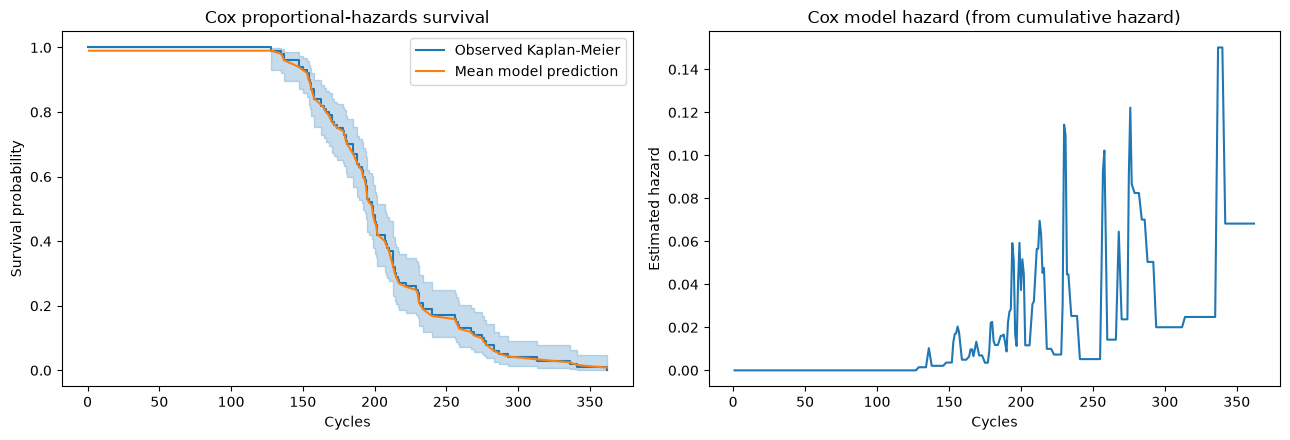

In [3]:
# Fit a Cox proportional-hazards model and check its proportional-hazards assumption.
from lifelines import CoxPHFitter

cox_model_data = pd.concat(
    [fd001_life[["T", "event"]], fd001_X], axis=1
)
cox_model = CoxPHFitter(penalizer=0.1)
cox_model.fit(cox_model_data, duration_col="T", event_col="event")

print("Model summary, coefficients, confidence intervals, and Wald tests:")
print(
    cox_model.summary[
        ["coef", "exp(coef)", "se(coef)", "coef lower 95%",
         "coef upper 95%", "z", "p"]
    ].to_string()
)
print("Partial AIC:", round(cox_model.AIC_partial_, 2))
print("Concordance index:", round(cox_model.concordance_index_, 3))
print("Proportional-hazards diagnostics:")
cox_model.check_assumptions(
    cox_model_data,
    show_plots=False,
    p_value_threshold=0.05,
)

cox_survival = cox_model.predict_survival_function(
    fd001_X, times=timeline
).mean(axis=1)
cox_cumulative_hazard = cox_model.predict_cumulative_hazard(
    fd001_X, times=timeline
).mean(axis=1)
cox_hazard = np.gradient(
    cox_cumulative_hazard.to_numpy(),
    timeline,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fd001_km.plot_survival_function(ax=axes[0], ci_show=True)
axes[0].plot(timeline, cox_survival, label="Mean model prediction")
axes[0].set(
    title="Cox proportional-hazards survival",
    xlabel="Cycles",
    ylabel="Survival probability",
)
axes[0].legend()

axes[1].plot(timeline, cox_hazard)
axes[1].set(
    title="Cox model hazard (from cumulative hazard)",
    xlabel="Cycles",
    ylabel="Estimated hazard",
)
fig.tight_layout()
plt.show()

Engine-level sample size: 100
Observed events: 100
Median cycles to failure: 199.0
Kaplan-Meier event-table summary:
          at_risk   observed  censored
count   67.000000  67.000000      67.0
mean    49.104478   1.492537       0.0
std     31.464812   0.859407       0.0
min      1.000000   0.000000       0.0
25%     20.000000   1.000000       0.0
50%     48.000000   1.000000       0.0
75%     76.500000   2.000000       0.0
max    100.000000   5.000000       0.0
Nelson-Aalen cumulative-hazard estimate and confidence intervals:
       FD001 engines  FD001 engines_lower_0.95  FD001 engines_upper_0.95
275.0       2.258409                  1.752983                  2.909561
276.0       2.358409                  1.824942                  3.047820
278.0       2.469520                  1.903567                  3.203738
283.0       2.737378                  2.086900                  3.590607
287.0       2.904044                  2.196162                  3.840096
293.0       3.104044        

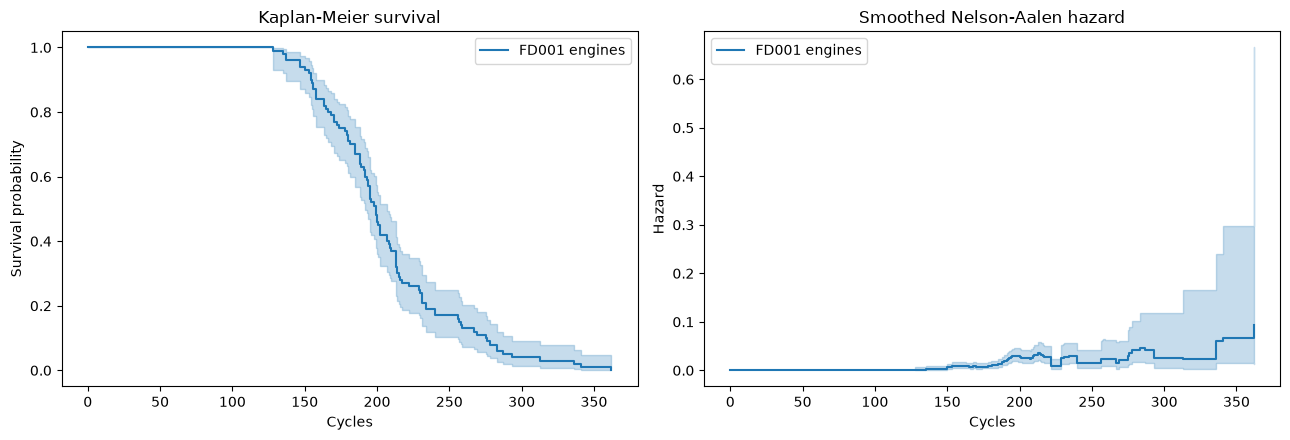

In [4]:
# Estimate FD001 survival with Kaplan-Meier and hazard with Nelson-Aalen.
from lifelines import KaplanMeierFitter, NelsonAalenFitter
from scipy.stats import norm

event_table = fd001_life[["T", "event"]]
kmf = KaplanMeierFitter().fit(
    event_table["T"],
    event_observed=event_table["event"],
    label="FD001 engines",
)
naf = NelsonAalenFitter().fit(
    event_table["T"],
    event_observed=event_table["event"],
    label="FD001 engines",
)

print("Engine-level sample size:", len(event_table))
print("Observed events:", int(event_table["event"].sum()))
print("Median cycles to failure:", kmf.median_survival_time_)
print("Kaplan-Meier event-table summary:")
print(kmf.event_table[["at_risk", "observed", "censored"]].describe())
print("Nelson-Aalen cumulative-hazard estimate and confidence intervals:")
print(
    pd.concat(
        [naf.cumulative_hazard_, naf.confidence_interval_],
        axis=1,
    ).tail(10).to_string()
)
print("KM/NA are nonparametric estimators, so regression coefficients do not apply.")

wald_time = 200
survival_at_time = float(kmf.predict(wald_time))
events_by_time = kmf.event_table.loc[:wald_time]
risk_sets = events_by_time["at_risk"]
observed_events = events_by_time["observed"]
valid_rows = risk_sets > observed_events
greenwood_sum = (
    observed_events[valid_rows]
    / (
        risk_sets[valid_rows]
        * (risk_sets[valid_rows] - observed_events[valid_rows])
    )
).sum()
greenwood_se = survival_at_time * np.sqrt(greenwood_sum)
wald_statistic = (survival_at_time - 0.5) / greenwood_se
wald_p_value = 2 * norm.sf(abs(wald_statistic))
wald_ci = np.clip(
    [
        survival_at_time - 1.96 * greenwood_se,
        survival_at_time + 1.96 * greenwood_se,
    ],
    0,
    1,
)
print(
    f"Wald test at {wald_time} cycles: H0: S(t) = 0.5; "
    f"S(t)={survival_at_time:.3f}, SE={greenwood_se:.3f}, "
    f"95% Wald CI=({wald_ci[0]:.3f}, {wald_ci[1]:.3f}), "
    f"z={wald_statistic:.3f}, p={wald_p_value:.4f}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
kmf.plot_survival_function(ax=axes[0], ci_show=True)
axes[0].set(
    title="Kaplan-Meier survival",
    xlabel="Cycles",
    ylabel="Survival probability",
)
naf.plot_hazard(ax=axes[1], bandwidth=8)
axes[1].set(
    title="Smoothed Nelson-Aalen hazard",
    xlabel="Cycles",
    ylabel="Hazard",
)
fig.tight_layout()
plt.show()

Test-set model comparison (100 engines):
              C-index  Cumulative/Dynamic AUC  MAE (cycles)    IAE    ISE      AIC      BIC
Model                                                                                      
Kaplan-Meier   0.7175                  0.8166       31.2933 8.0390 0.7973      NaN      NaN
Cox PH         0.7100                  0.7997       32.3554 8.1555 0.8176 740.4214 779.4989
AIC/BIC are not defined for Kaplan-Meier here (shown as NaN).
Cox BIC uses the partial log-likelihood and number of sensor coefficients.
IAE/ISE integrate absolute/squared error between mean predicted and actual test-RUL survival.


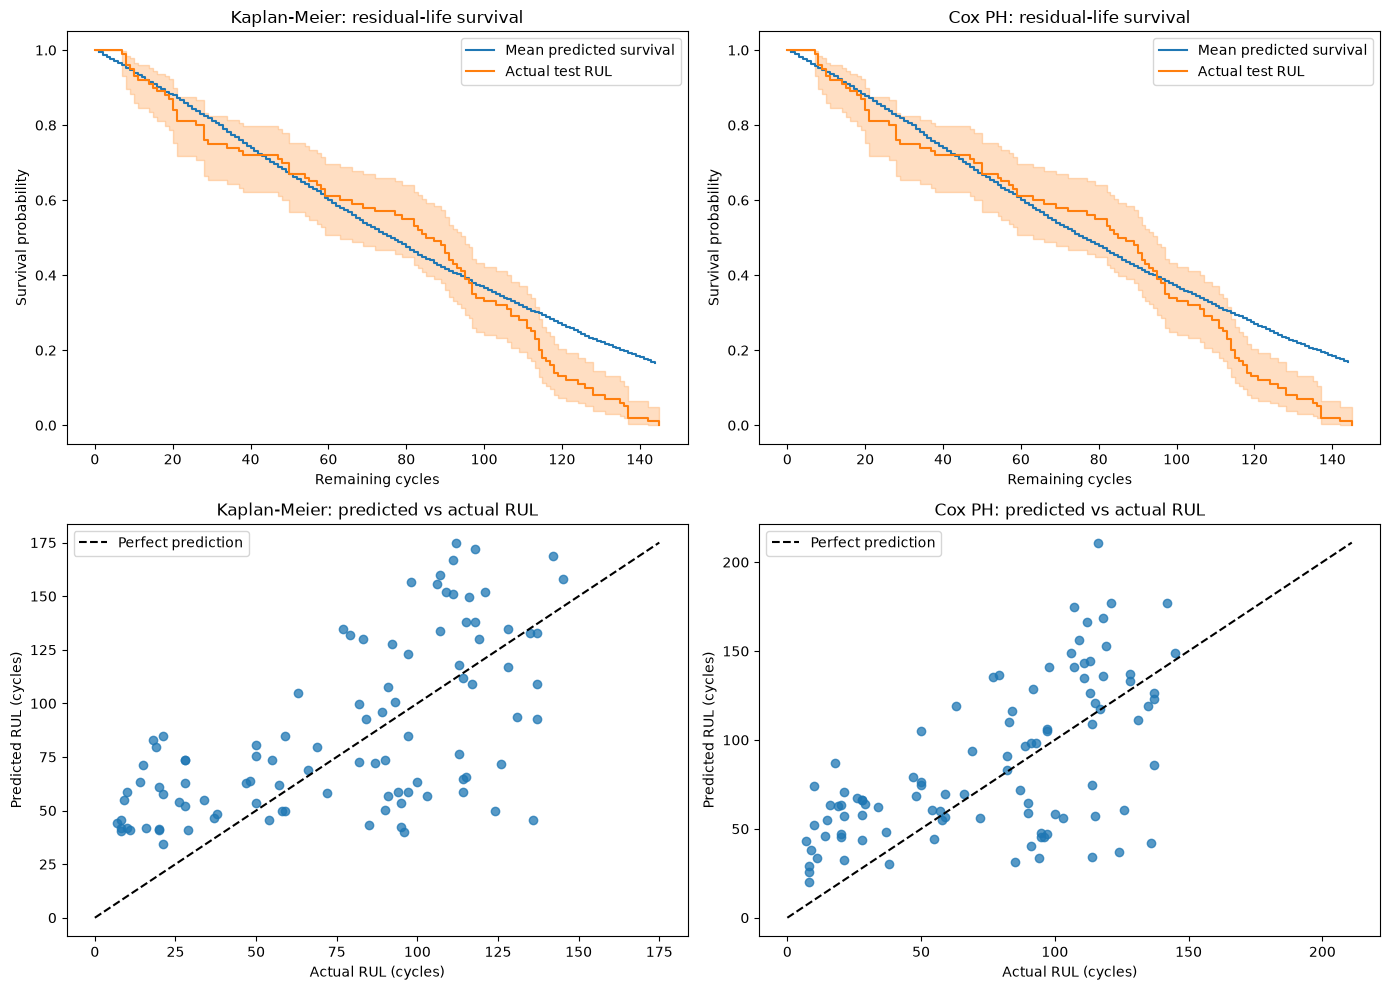

In [5]:
# Compare FD001 test RUL predictions from train-fitted Kaplan-Meier and Cox PH models.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.metrics import mean_absolute_error, roc_auc_score

columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]

train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)
actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"],
)["RUL"].to_numpy()

train_baseline = (
    train_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False)
    .first()
)
train_failure_times = (
    train_raw.groupby("engine_id", as_index=False)["cycle"]
    .max()
    .rename(columns={"cycle": "T"})
)
train_life = train_baseline[["engine_id", *columns[5:]]].merge(
    train_failure_times,
    on="engine_id",
    validate="one_to_one",
)

sensor_cols = [
    col for col in columns[5:]
    if train_life[col].nunique() > 1
]
train_mean = train_life[sensor_cols].mean()
train_sd = train_life[sensor_cols].std(ddof=0).replace(0, 1)
X_train = (train_life[sensor_cols] - train_mean) / train_sd

cox_train = X_train.copy()
cox_train["T"] = train_life["T"]
cox_train["event"] = 1

km_model = KaplanMeierFitter().fit(
    train_life["T"],
    event_observed=np.ones(len(train_life)),
)
cox_model = CoxPHFitter(penalizer=0.1).fit(
    cox_train,
    duration_col="T",
    event_col="event",
)

test_baseline = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False)
    .first()
    .sort_values("engine_id")
)
test_age = (
    test_raw.groupby("engine_id")["cycle"]
    .max()
    .sort_index()
    .to_numpy()
)

assert len(train_life) == 100
assert len(test_baseline) == len(test_age) == len(actual_rul) == 100
assert test_baseline["engine_id"].to_list() == list(range(1, 101))

X_test = (
    test_baseline.set_index("engine_id")
    .loc[range(1, 101), sensor_cols]
    - train_mean
) / train_sd

max_train_T = int(train_life["T"].max())
rul_grid = np.arange(0, max_train_T + 1)

km_at_test_age = km_model.predict(test_age).to_numpy()
assert np.all(km_at_test_age > 0), "A test age is beyond the KM survival support."

km_survival = np.vstack([
    np.asarray(km_model.predict(age + rul_grid)) / survival_at_age
    for age, survival_at_age in zip(test_age, km_at_test_age)
])
km_survival[:, 0] = 1.0

cox_survival = cox_model.predict_survival_function(
    X_test,
    times=rul_grid,
    conditional_after=test_age.tolist(),
).to_numpy().T

supported_rul = np.maximum(0, max_train_T - test_age)
outside_support = rul_grid[None, :] > supported_rul[:, None]
km_survival[outside_support] = 0.0
cox_survival[outside_support] = 0.0
km_survival = np.clip(km_survival, 0.0, 1.0)
cox_survival = np.clip(cox_survival, 0.0, 1.0)

predicted_rul = {
    "Kaplan-Meier": np.trapezoid(km_survival, rul_grid, axis=1),
    "Cox PH": np.trapezoid(cox_survival, rul_grid, axis=1),
}

actual_km = KaplanMeierFitter().fit(
    actual_rul,
    event_observed=np.ones(len(actual_rul)),
    label="Actual test RUL",
)
metric_horizons = np.arange(1, int(actual_rul.max()))
actual_survival = np.asarray(actual_km.predict(metric_horizons))

survival_predictions = {
    "Kaplan-Meier": km_survival,
    "Cox PH": cox_survival,
}
results = []

for model_name, survival_curves in survival_predictions.items():
    dynamic_auc_values = []

    for horizon in metric_horizons:
        failed_by_horizon = (actual_rul <= horizon).astype(int)
        if np.unique(failed_by_horizon).size == 2:
            predicted_risk = 1.0 - survival_curves[:, horizon]
            dynamic_auc_values.append(
                roc_auc_score(failed_by_horizon, predicted_risk)
            )

    predicted_mean_survival = survival_curves.mean(axis=0)[metric_horizons]
    is_km = model_name == "Kaplan-Meier"

    results.append({
        "Model": model_name,
        "C-index": concordance_index(
            actual_rul,
            predicted_rul[model_name],
        ),
        "Cumulative/Dynamic AUC": np.mean(dynamic_auc_values),
        "MAE (cycles)": mean_absolute_error(
            actual_rul,
            predicted_rul[model_name],
        ),
        "IAE": np.trapezoid(
            np.abs(predicted_mean_survival - actual_survival),
            metric_horizons,
        ),
        "ISE": np.trapezoid(
            (predicted_mean_survival - actual_survival) ** 2,
            metric_horizons,
        ),
        "AIC": np.nan if is_km else cox_model.AIC_partial_,
        "BIC": (
            np.nan if is_km else
            -2 * cox_model.log_likelihood_
            + len(sensor_cols) * np.log(len(train_life))
        ),
    })

comparison = pd.DataFrame(results).set_index("Model")
print("Test-set model comparison (100 engines):")
print(comparison.to_string(float_format=lambda value: f"{value:.4f}"))
print("AIC/BIC are not defined for Kaplan-Meier here (shown as NaN).")
print("Cox BIC uses the partial log-likelihood and number of sensor coefficients.")
print("IAE/ISE integrate absolute/squared error between mean predicted and actual test-RUL survival.")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for axis, model_name, curves in [
    (axes[0, 0], "Kaplan-Meier", km_survival),
    (axes[0, 1], "Cox PH", cox_survival),
]:
    axis.step(
        metric_horizons,
        curves.mean(axis=0)[metric_horizons],
        where="post",
        label="Mean predicted survival",
    )
    actual_km.plot_survival_function(ax=axis, ci_show=True)
    axis.set(
        title=f"{model_name}: residual-life survival",
        xlabel="Remaining cycles",
        ylabel="Survival probability",
    )
    axis.legend()

for axis, model_name in zip(axes[1], predicted_rul):
    predictions = predicted_rul[model_name]
    limit = max(int(actual_rul.max()), int(np.ceil(predictions.max())))
    axis.scatter(actual_rul, predictions, alpha=0.75)
    axis.plot([0, limit], [0, limit], "k--", label="Perfect prediction")
    axis.set(
        title=f"{model_name}: predicted vs actual RUL",
        xlabel="Actual RUL (cycles)",
        ylabel="Predicted RUL (cycles)",
    )
    axis.legend()

fig.tight_layout()
plt.show()

c:\Users\User\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FD001 test comparison (100 engines; predicted RUL is integrated residual survival):
                        C-index  Cumulative/Dynamic AUC  MAE (cycles)    IAE    ISE      AIC      BIC
Model                                                                                                
Kaplan-Meier             0.7175                  0.8166       31.2933 8.0390 0.7973      NaN      NaN
Cox PH                   0.7100                  0.7997       32.3554 8.1555 0.8176 740.4214 779.4989
Random survival forest   0.7159                  0.7973       31.9272 8.5594 0.9416      NaN      NaN
AIC/BIC are not likelihood criteria for Kaplan-Meier or RSF and are shown as NaN.
Cox AIC is partial AIC; Cox BIC uses partial log-likelihood and sensor coefficient count.
IAE/ISE compare mean predicted residual survival with empirical survival of RUL_FD001.
SHAP explains the Random-Forest surrogate of RSF risk (higher score means higher risk). Surrogate training R-squared: 0.887
Top mean absolute SHAP 

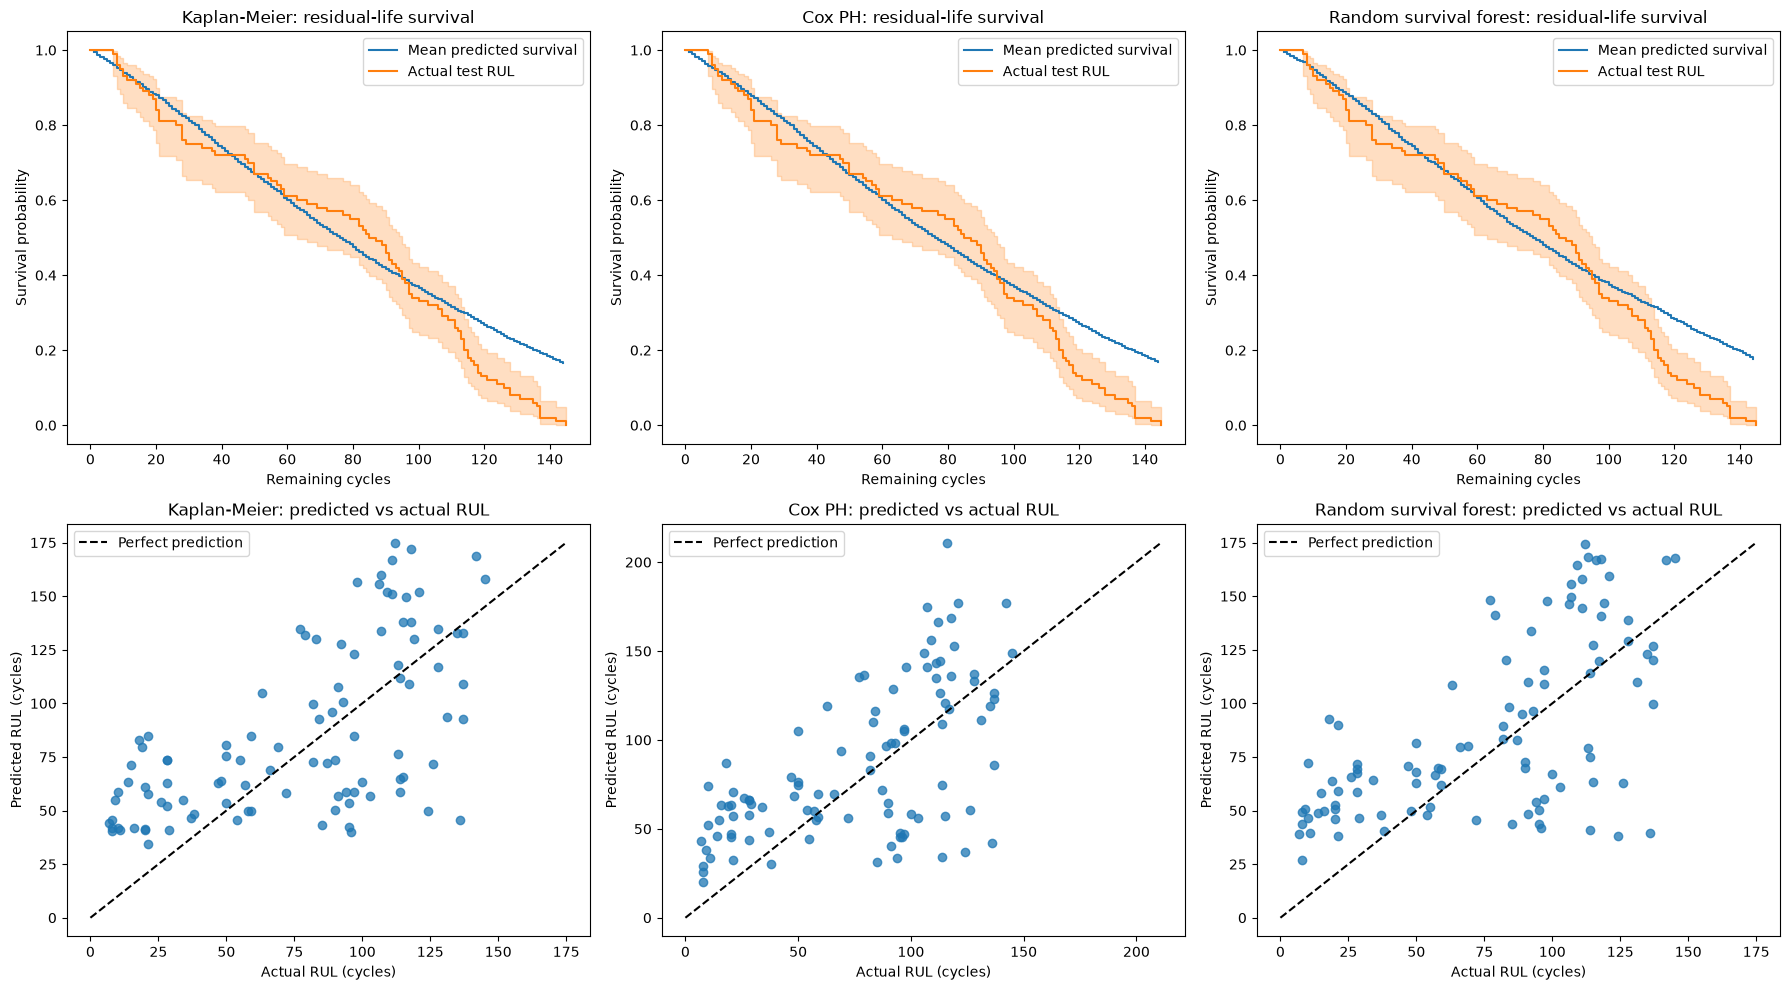

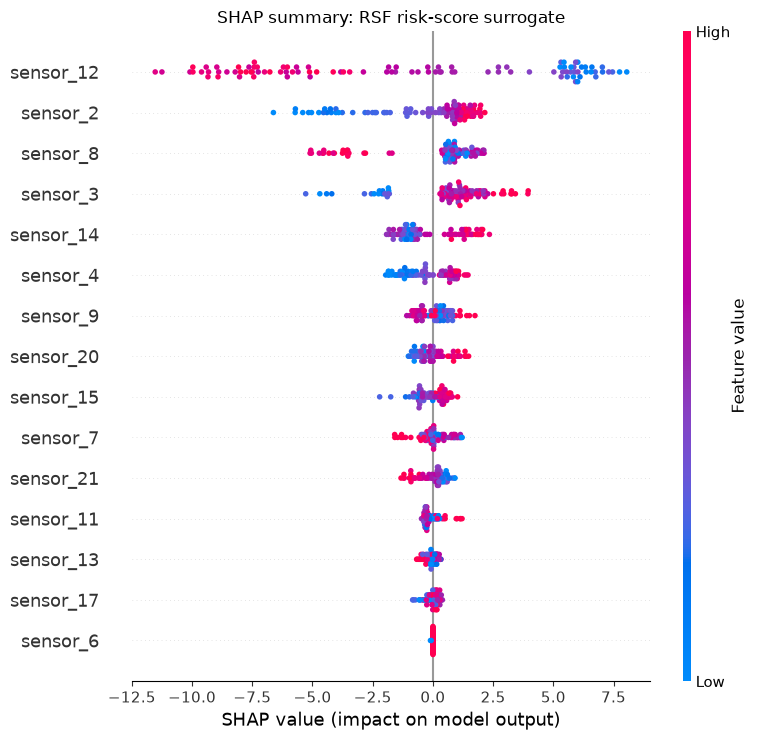

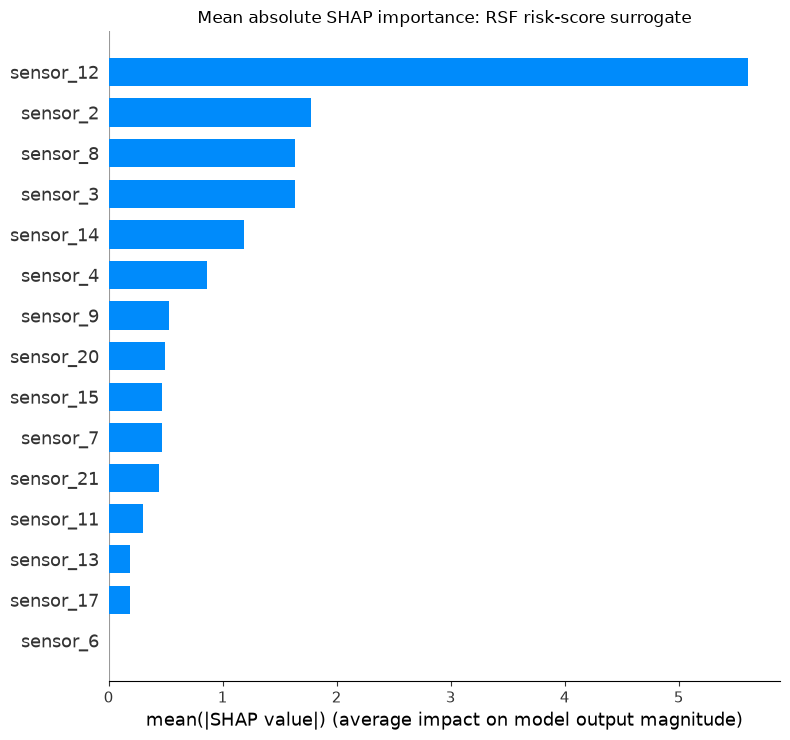

In [1]:
# Compare Kaplan-Meier, Cox PH, and random survival forest predictions for FD001, with SHAP TreeExplainer analysis.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, roc_auc_score
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy()

# Use one cycle-1 sensor record for each engine; training T is its observed failure cycle.
train_baseline = (
    train_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first()
)
train_end = (
    train_raw.groupby("engine_id", as_index=False)["cycle"]
    .max().rename(columns={"cycle": "T"})
)
train_life = train_baseline[["engine_id", *columns[5:]]].merge(
    train_end, on="engine_id", validate="one_to_one"
)
sensor_cols = [col for col in columns[5:] if train_life[col].nunique() > 1]
train_mean = train_life[sensor_cols].mean()
train_sd = train_life[sensor_cols].std(ddof=0).replace(0, 1)
X_train = (train_life[sensor_cols] - train_mean) / train_sd
assert len(train_raw) == 20631 and len(train_life) == 100

# Fit all models on the same 100 complete training lifetimes and baseline sensors.
train_events = np.ones(len(train_life), dtype=bool)
km_model = KaplanMeierFitter().fit(
    train_life["T"], event_observed=train_events
)
cox_train = X_train.copy()
cox_train["T"] = train_life["T"]
cox_train["event"] = 1
cox_model = CoxPHFitter(penalizer=0.1).fit(
    cox_train, duration_col="T", event_col="event"
)
rsf_model = RandomSurvivalForest(
    n_estimators=300,
    min_samples_leaf=3,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42,
)
rsf_model.fit(
    X_train,
    Surv.from_arrays(train_events, train_life["T"].to_numpy()),
)

# Align each test RUL target to its engine's final test cycle and baseline sensor row.
test_baseline = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first().sort_values("engine_id")
)
test_age = (
    test_raw.groupby("engine_id")["cycle"].max().sort_index().to_numpy()
)
assert len(test_baseline) == len(test_age) == len(actual_rul) == 100
assert test_baseline["engine_id"].to_list() == list(range(1, 101))
X_test = (
    test_baseline.set_index("engine_id").loc[range(1, 101), sensor_cols]
    - train_mean
) / train_sd

# Convert fitted survival curves to residual survival conditional on reaching each test age.
max_train_T = int(train_life["T"].max())
rul_grid = np.arange(0, max_train_T + 1)
km_at_age = km_model.predict(test_age).to_numpy()
assert np.all(km_at_age > 0), "A test age is beyond the training KM survival support."
km_survival = np.vstack([
    np.asarray(km_model.predict(age + rul_grid)) / survival_at_age
    for age, survival_at_age in zip(test_age, km_at_age)
])
km_survival[:, 0] = 1.0
cox_survival = cox_model.predict_survival_function(
    X_test, times=rul_grid, conditional_after=test_age.tolist()
).to_numpy().T
rsf_functions = rsf_model.predict_survival_function(X_test)
rsf_at_age = np.asarray([
    survival_function(age)
    for survival_function, age in zip(rsf_functions, test_age)
])
assert np.all(rsf_at_age > 0), "A test age is beyond an RSF subject's survival support."
rsf_survival = np.vstack([
    survival_function(np.minimum(age + rul_grid, max_train_T)) / survival_at_age
    for survival_function, age, survival_at_age
    in zip(rsf_functions, test_age, rsf_at_age)
])

# Predictions are restricted to the remaining training-time support; integrate survival for mean RUL.
supported_rul = np.maximum(0, max_train_T - test_age)
outside_support = rul_grid[None, :] > supported_rul[:, None]
for survival_curves in (km_survival, cox_survival, rsf_survival):
    survival_curves[outside_support] = 0.0
    np.clip(survival_curves, 0.0, 1.0, out=survival_curves)
predicted_rul = {
    "Kaplan-Meier": np.trapezoid(km_survival, rul_grid, axis=1),
    "Cox PH": np.trapezoid(cox_survival, rul_grid, axis=1),
    "Random survival forest": np.trapezoid(rsf_survival, rul_grid, axis=1),
}

# Compare the same requested scores on all 100 engines against the supplied RUL targets.
actual_km = KaplanMeierFitter().fit(
    actual_rul, event_observed=np.ones(len(actual_rul)), label="Actual test RUL"
)
metric_horizons = np.arange(1, int(actual_rul.max()))
actual_survival = np.asarray(actual_km.predict(metric_horizons))
survival_predictions = {
    "Kaplan-Meier": km_survival,
    "Cox PH": cox_survival,
    "Random survival forest": rsf_survival,
}
results = []
for model_name, survival_curves in survival_predictions.items():
    auc_values = []
    for horizon in metric_horizons:
        failed_by_horizon = (actual_rul <= horizon).astype(int)
        if np.unique(failed_by_horizon).size == 2:
            predicted_risk = 1.0 - survival_curves[:, horizon]
            auc_values.append(roc_auc_score(failed_by_horizon, predicted_risk))
    mean_survival = survival_curves.mean(axis=0)[metric_horizons]
    is_cox = model_name == "Cox PH"
    results.append({
        "Model": model_name,
        "C-index": concordance_index(actual_rul, predicted_rul[model_name]),
        "Cumulative/Dynamic AUC": np.mean(auc_values),
        "MAE (cycles)": mean_absolute_error(actual_rul, predicted_rul[model_name]),
        "IAE": np.trapezoid(np.abs(mean_survival - actual_survival), metric_horizons),
        "ISE": np.trapezoid((mean_survival - actual_survival) ** 2, metric_horizons),
        "AIC": np.nan if not is_cox else cox_model.AIC_partial_,
        "BIC": (
            np.nan if not is_cox else
            -2 * cox_model.log_likelihood_
            + len(sensor_cols) * np.log(len(train_life))
        ),
    })
comparison = pd.DataFrame(results).set_index("Model")
print("FD001 test comparison (100 engines; predicted RUL is integrated residual survival):")
print(comparison.to_string(float_format=lambda value: f"{value:.4f}"))
print("AIC/BIC are not likelihood criteria for Kaplan-Meier or RSF and are shown as NaN.")
print("Cox AIC is partial AIC; Cox BIC uses partial log-likelihood and sensor coefficient count.")
print("IAE/ISE compare mean predicted residual survival with empirical survival of RUL_FD001.")

# TreeExplainer cannot parse scikit-survival's RandomSurvivalForest directly; explain an RF surrogate of its risk score.
rsf_train_risk = rsf_model.predict(X_train)
risk_surrogate = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=0.8,
    n_jobs=-1,
    random_state=42,
).fit(X_train, rsf_train_risk)
shap_background = shap.sample(X_train, min(100, len(X_train)), random_state=42)
tree_explainer = shap.TreeExplainer(
    risk_surrogate,
    data=shap_background,
    feature_perturbation="interventional",
)
shap_values = tree_explainer(X_test, check_additivity=False)
print(
    "SHAP explains the Random-Forest surrogate of RSF risk (higher score means higher risk). "
    "Surrogate training R-squared:",
    round(risk_surrogate.score(X_train, rsf_train_risk), 3),
)
shap_importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0), index=sensor_cols
).sort_values(ascending=False)
print("Top mean absolute SHAP features:")
print(shap_importance.head(10).to_string())

# Plot predicted versus actual survival and per-engine RUL, followed by SHAP summary and importance plots.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for axis, model_name, survival_curves in zip(
    axes[0], survival_predictions, survival_predictions.values()
):
    axis.step(
        metric_horizons,
        survival_curves.mean(axis=0)[metric_horizons],
        where="post",
        label="Mean predicted survival",
    )
    actual_km.plot_survival_function(ax=axis, ci_show=True)
    axis.set(
        title=f"{model_name}: residual-life survival",
        xlabel="Remaining cycles",
        ylabel="Survival probability",
    )
    axis.legend()
for axis, model_name in zip(axes[1], predicted_rul):
    predictions = predicted_rul[model_name]
    limit = max(int(actual_rul.max()), int(np.ceil(predictions.max())))
    axis.scatter(actual_rul, predictions, alpha=0.75)
    axis.plot([0, limit], [0, limit], "k--", label="Perfect prediction")
    axis.set(
        title=f"{model_name}: predicted vs actual RUL",
        xlabel="Actual RUL (cycles)",
        ylabel="Predicted RUL (cycles)",
    )
    axis.legend()
fig.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values.values, X_test, show=False)
plt.title("SHAP summary: RSF risk-score surrogate")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values.values, X_test, plot_type="bar", show=False)
plt.title("Mean absolute SHAP importance: RSF risk-score surrogate")
plt.tight_layout()
plt.show()


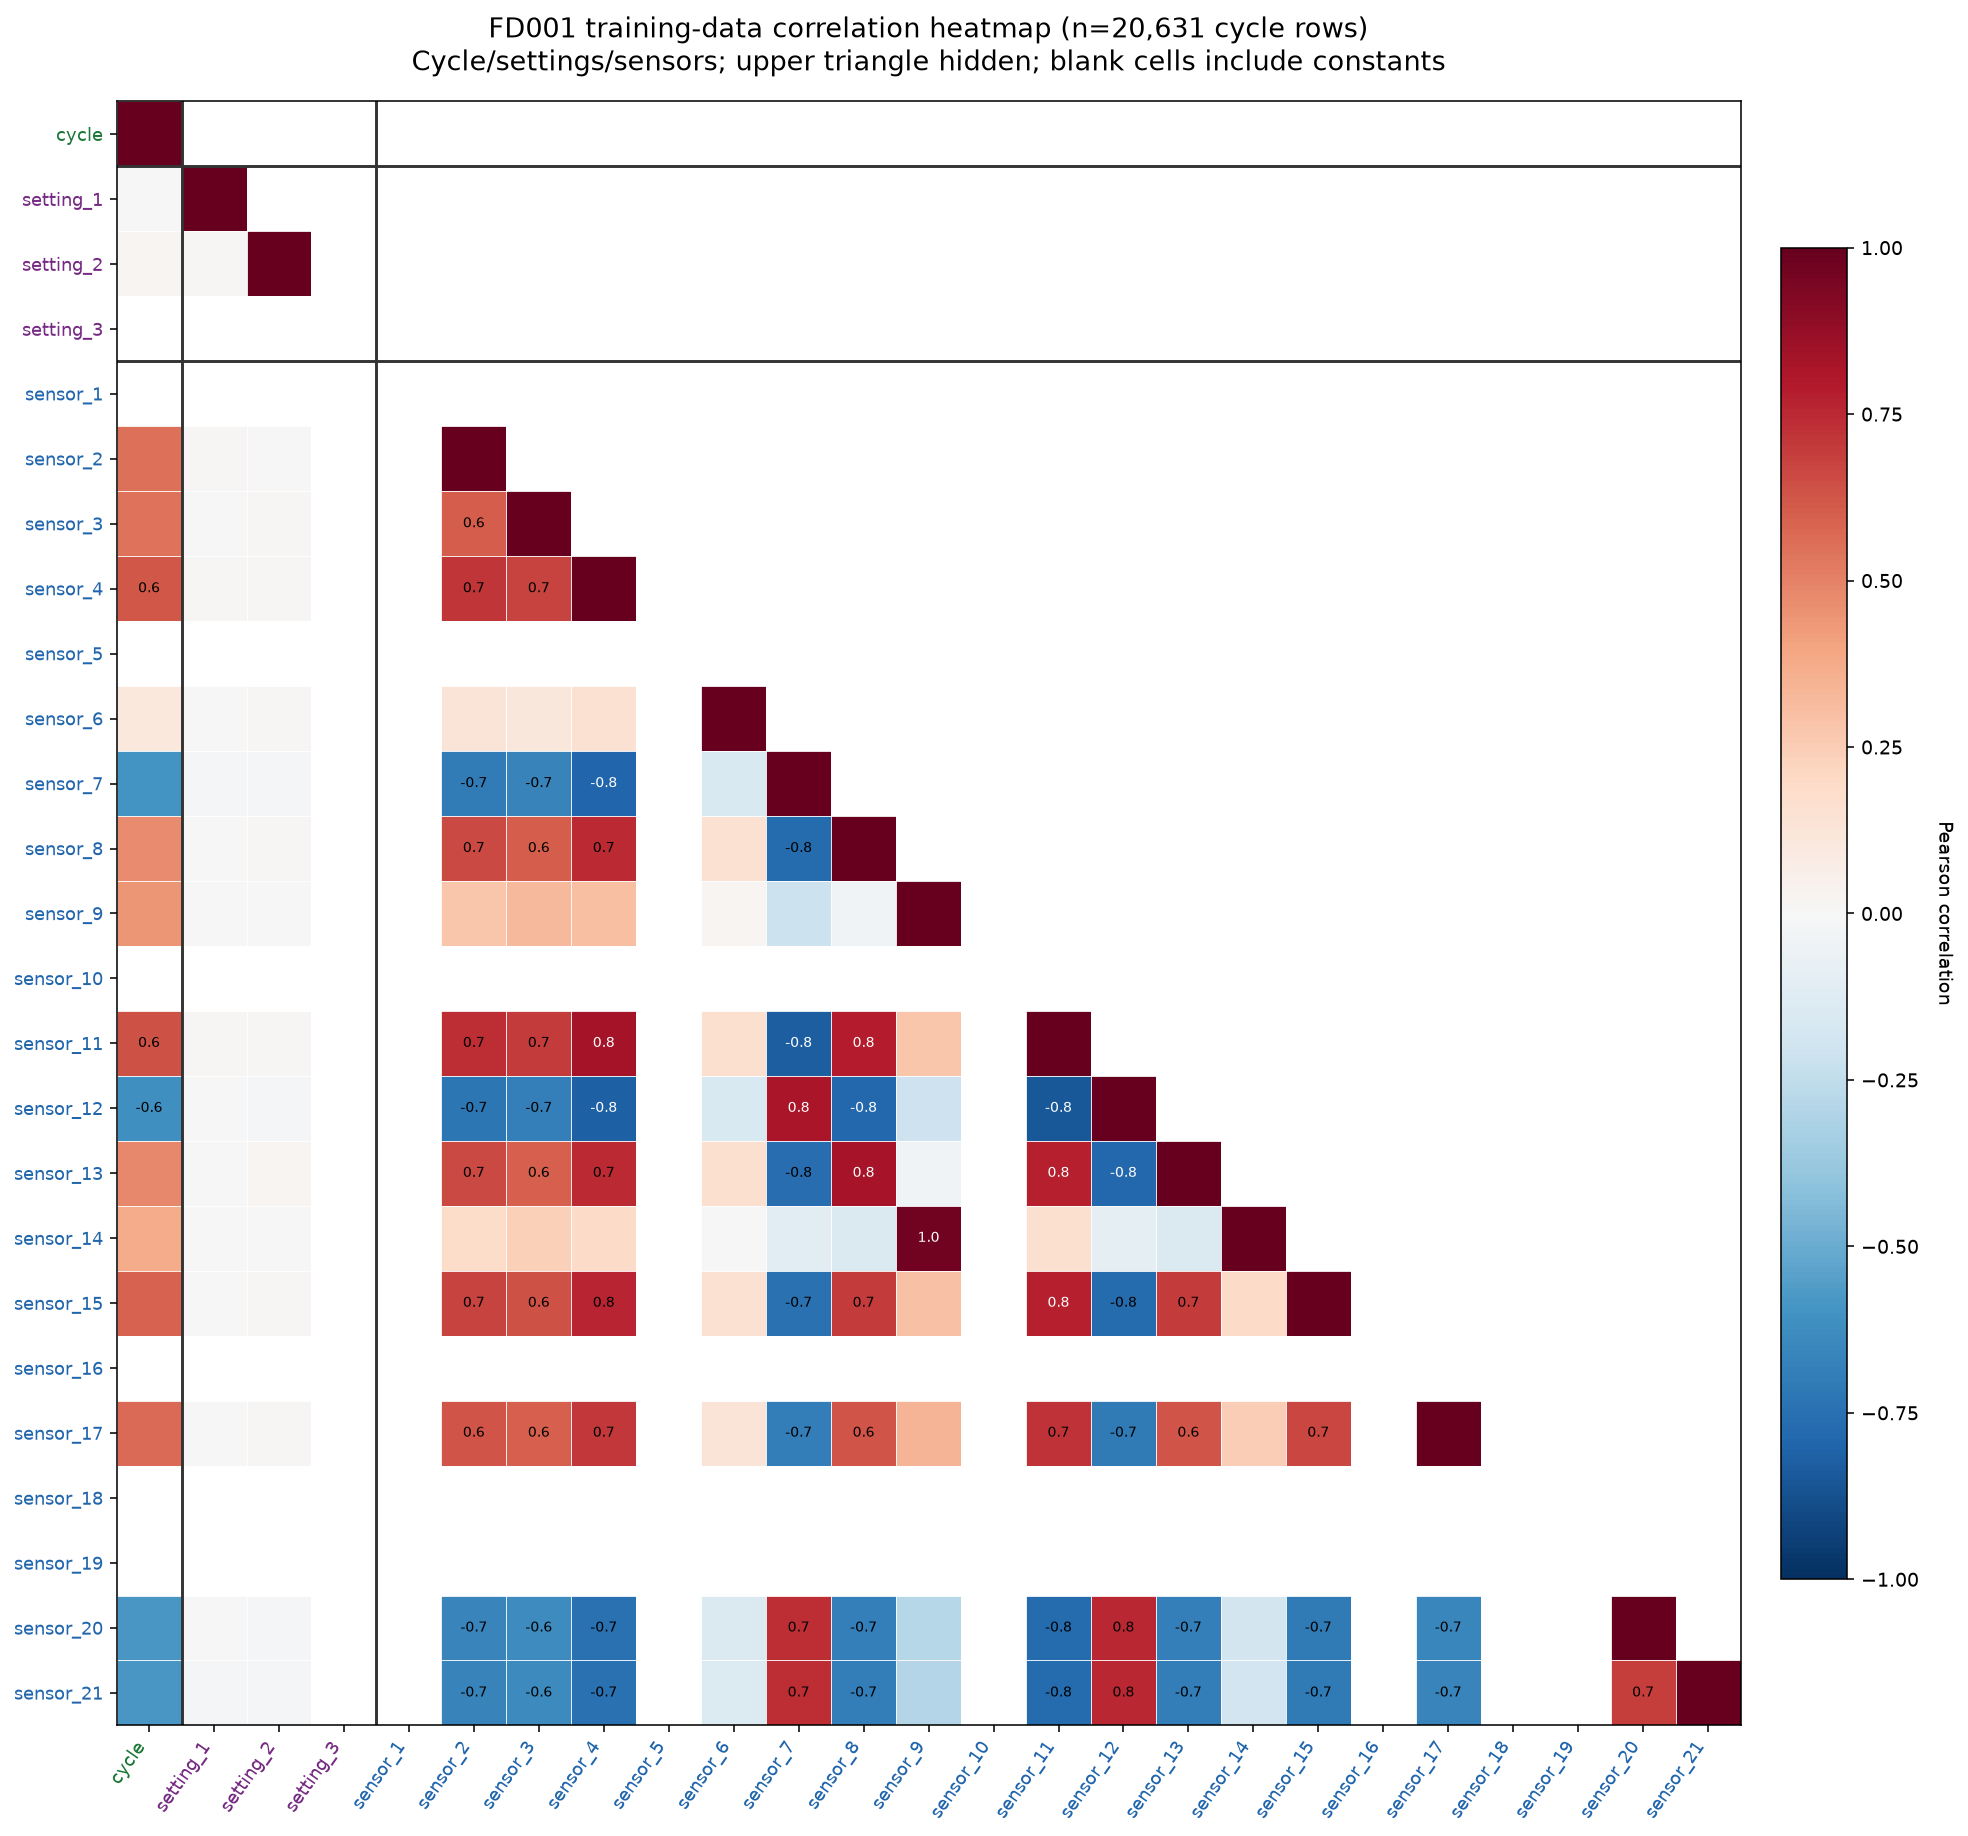

In [6]:
# Plot a Pearson-correlation heatmap for FD001 training variables, excluding engine ID.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fd001_columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
fd001_train_for_corr = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=fd001_columns,
)
# Engine ID labels engines rather than measuring an engine condition, so do not correlate it.
correlation_variables = [
    column for column in fd001_columns if column != "engine_id"
]
correlation_matrix = fd001_train_for_corr[correlation_variables].corr(method="pearson")
correlation_values = correlation_matrix.to_numpy()
constant_variables = [
    column for column in correlation_variables
    if fd001_train_for_corr[column].nunique() == 1
]
upper_triangle = np.triu(np.ones_like(correlation_values, dtype=bool), k=1)
masked_cells = upper_triangle | ~np.isfinite(correlation_values)
masked_correlations = np.ma.array(correlation_values, mask=masked_cells)
print("Constant variables (their correlations are undefined):", constant_variables)

fig, ax = plt.subplots(figsize=(16, 13), constrained_layout=True)
image = ax.imshow(
    masked_correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    interpolation="nearest",
)
ax.set_xticks(np.arange(len(correlation_variables)))
ax.set_yticks(np.arange(len(correlation_variables)))
ax.set_xticklabels(correlation_variables, rotation=55, ha="right", fontsize=9)
ax.set_yticklabels(correlation_variables, fontsize=9)
ax.set_xticks(np.arange(-0.5, len(correlation_variables), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(correlation_variables), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.45)
ax.tick_params(which="minor", bottom=False, left=False)

# Delineate cycle, operational settings, and sensor measurements.
for boundary in (0.5, 3.5):
    ax.axhline(boundary, color="#333333", linewidth=1.5)
    ax.axvline(boundary, color="#333333", linewidth=1.5)
for index, variable in enumerate(correlation_variables):
    if variable == "cycle":
        color = "#1b7837"
    elif variable.startswith("setting_"):
        color = "#762a83"
    else:
        color = "#2166ac"
    ax.get_xticklabels()[index].set_color(color)
    ax.get_yticklabels()[index].set_color(color)

# Label stronger off-diagonal correlations without overcrowding the full matrix.
for row in range(len(correlation_variables)):
    for col in range(row):
        value = correlation_values[row, col]
        if abs(value) >= 0.6:
            ax.text(
                col, row, f"{value:.1f}",
                ha="center", va="center", fontsize=7,
                color="white" if abs(value) >= 0.78 else "black",
            )

colorbar = fig.colorbar(image, ax=ax, shrink=0.82, pad=0.02)
colorbar.set_label("Pearson correlation", rotation=270, labelpad=18)
ax.set_title(
    f"FD001 training-data correlation heatmap (n={len(fd001_train_for_corr):,} cycle rows)\n"
    "Cycle/settings/sensors; upper triangle hidden; blank cells include constants",
    fontsize=14,
    pad=16,
)
plt.show()
